# Exploration: Dataset 1 and Dataset 2

This notebook is optional extra exploration, done after the data audit (`Data Audit.ipynb`, `docs/audit.md`). The goal is to understand the data before the pipeline is built. Nothing in the data is changed.

- Data used: Dataset 1 (`Training dataset 1.csv`) and Dataset 2 (`Training dataset 2.csv`) only.
- The Test set is not used. It stays untouched until all choices and thresholds are frozen.
- The full explanation of each step is in `docs/exploration.md`. The notes here are short.

Steps:
0. Setup and attack windows
1. Drift check within Dataset 1 (1a to 1d, then 1e further down)
2. Rare pumps 6 and 11
3. Near-duplicate sensors
4. Plot: first normal week of Dataset 1
5. Attack 1 (13 to 16 Sep 2016)

## 0. Setup and attack windows

Why: both training files are needed with clean column names and real dates.

What the code does: loads Dataset 1 (`dfT1`) and Dataset 2 (`dfT2`) from `../data/`, strips the spaces from the column names, and turns `DATETIME` into real dates (format day/month/year hour).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

dfT1 = pd.read_csv("../data/Training dataset 1.csv")
dfT2 = pd.read_csv("../data/Training dataset 2.csv")

dfT1.columns = dfT1.columns.str.strip()
dfT2.columns = dfT2.columns.str.strip()

dfT1["DATETIME"] = pd.to_datetime(dfT1["DATETIME"], format="%d/%m/%y %H")
dfT2["DATETIME"] = pd.to_datetime(dfT2["DATETIME"], format="%d/%m/%y %H")

### Build the attack windows

This builds the 7 real attack windows for Dataset 2 from the BATADAL site (`attacks`). Hours are counted including both the start and end hour, so the 7 windows add up to 492 hours. The file itself only labels 219 hours as attacks (found in the audit).

In [2]:
attacks = pd.DataFrame({
    "attack_id": [1, 2, 3, 4, 5, 6, 7],
    "real_start": pd.to_datetime(["2016-09-13 23:00", "2016-09-26 11:00", "2016-10-09 09:00",
                                  "2016-10-29 19:00", "2016-11-26 17:00", "2016-12-06 07:00",
                                  "2016-12-14 15:00"]),
    "real_end": pd.to_datetime(["2016-09-16 00:00", "2016-09-27 10:00", "2016-10-11 20:00",
                                "2016-11-02 16:00", "2016-11-29 04:00", "2016-12-10 04:00",
                                "2016-12-19 04:00"]),
})
attacks["real_hours"] = (attacks["real_end"] - attacks["real_start"]).dt.total_seconds() / 3600 + 1
print(attacks)
print(attacks["real_hours"].sum())

   attack_id          real_start            real_end  real_hours
0          1 2016-09-13 23:00:00 2016-09-16 00:00:00        50.0
1          2 2016-09-26 11:00:00 2016-09-27 10:00:00        24.0
2          3 2016-10-09 09:00:00 2016-10-11 20:00:00        60.0
3          4 2016-10-29 19:00:00 2016-11-02 16:00:00        94.0
4          5 2016-11-26 17:00:00 2016-11-29 04:00:00        60.0
5          6 2016-12-06 07:00:00 2016-12-10 04:00:00        94.0
6          7 2016-12-14 15:00:00 2016-12-19 04:00:00       110.0
492.0


### Extra cell: time blocks (repeat)

This cell has the same code and the same output as the cell in step 1a below. It does not match a separate step.

In [3]:
n = len(dfT1)
cut1 = int(n * 0.6)
cut2 = int(n * 0.8)

block_a = dfT1.iloc[:cut1]
block_b = dfT1.iloc[cut1:cut2]
block_c = dfT1.iloc[cut2:]

print("Total rows:", n)
print("Block A:", block_a["DATETIME"].min(), "to", block_a["DATETIME"].max(), "-", len(block_a), "rows")
print("Block B:", block_b["DATETIME"].min(), "to", block_b["DATETIME"].max(), "-", len(block_b), "rows")
print("Block C:", block_c["DATETIME"].min(), "to", block_c["DATETIME"].max(), "-", len(block_c), "rows")

Total rows: 8761
Block A: 2014-01-06 00:00:00 to 2014-08-12 23:00:00 - 5256 rows
Block B: 2014-08-13 00:00:00 to 2014-10-24 23:00:00 - 1752 rows
Block C: 2014-10-25 00:00:00 to 2015-01-06 00:00:00 - 1753 rows


### Save the attack windows

Why: the 7 real attack windows are needed later (step 2 and step 5). Saving them to a file means they can be reused without typing them again.

What the code does: saves the `attacks` table to `data/attack_windows_dataset2.csv`, with one row per attack: `attack_id`, `real_start`, `real_end`, `real_hours`.

In [4]:
attacks.to_csv("../data/attack_windows_dataset2.csv", index=False)

## 1. Drift check within Dataset 1

Why: drift means "normal" behavior changes over time. The detectors learn normal behavior from the first 60% of Dataset 1, and alarm thresholds are set on the last 20%. If normal behavior changed over the year, the models could raise false alarms and the thresholds could be set wrong. The 60/20/20 split is not fixed yet, so this check also shows whether that split is reasonable.

### 1a. Make three time blocks

What the code does: cuts Dataset 1 by row position at 60% and 80%. No gaps and no scaling. This split is only for exploration, not the final pipeline split. Note: 0.6 and 0.8 are cut points, not block sizes. The blocks are 60%, 20%, and 20%.

In [5]:
n = len(dfT1)
cut1 = int(n * 0.6)
cut2 = int(n * 0.8)

block_a = dfT1.iloc[:cut1]
block_b = dfT1.iloc[cut1:cut2]
block_c = dfT1.iloc[cut2:]

print("Total rows:", n)
print("Block A:", block_a["DATETIME"].min(), "to", block_a["DATETIME"].max(), "-", len(block_a), "rows")
print("Block B:", block_b["DATETIME"].min(), "to", block_b["DATETIME"].max(), "-", len(block_b), "rows")
print("Block C:", block_c["DATETIME"].min(), "to", block_c["DATETIME"].max(), "-", len(block_c), "rows")

Total rows: 8761
Block A: 2014-01-06 00:00:00 to 2014-08-12 23:00:00 - 5256 rows
Block B: 2014-08-13 00:00:00 to 2014-10-24 23:00:00 - 1752 rows
Block C: 2014-10-25 00:00:00 to 2015-01-06 00:00:00 - 1753 rows


**What this shows:** 8,761 rows in total.
- Block A: 2014-01-06 00:00 to 2014-08-12 23:00, 5,256 rows (winter to summer).
- Block B: 2014-08-13 00:00 to 2014-10-24 23:00, 1,752 rows (late summer to fall).
- Block C: 2014-10-25 00:00 to 2015-01-06 00:00, 1,753 rows (late fall to early winter).

The blocks follow each other with no gaps and no overlap. Caution: each block covers a different season, so any change between blocks could also be a season effect.

### 1b. Average of each sensor per block

Why: if a sensor's average moves a lot between blocks, normal behavior has changed.

What the code does: takes the 43 sensor columns (`sensor_cols`, 31 continuous and 12 on/off) and prints the average of each one in blocks A, B, and C. For on/off (`S_`) columns, the average is the share of hours the pump or valve is on.

In [6]:
sensor_cols = [c for c in dfT1.columns if c not in ["DATETIME", "ATT_FLAG"]]
print(len(sensor_cols))

means = pd.DataFrame({
    "A": block_a[sensor_cols].mean(),
    "B": block_b[sensor_cols].mean(),
    "C": block_c[sensor_cols].mean(),
})
print(means.round(2))

43
             A       B       C
L_T1      2.67    2.68    2.71
L_T2      3.29    3.28    3.28
L_T3      4.20    4.20    4.20
L_T4      3.57    3.55    3.58
L_T5      2.75    2.75    2.75
L_T6      5.37    5.37    5.37
L_T7      3.29    3.31    3.35
F_PU1   100.97  100.99  100.74
S_PU1     1.00    1.00    1.00
F_PU2    69.38   69.08   70.10
S_PU2     0.73    0.73    0.74
F_PU3     0.00    0.00    0.00
S_PU3     0.00    0.00    0.00
F_PU4    14.61   14.44   14.49
S_PU4     0.42    0.42    0.42
F_PU5     0.00    0.00    0.00
S_PU5     0.00    0.00    0.00
F_PU6     0.10    0.00    0.04
S_PU6     0.00    0.00    0.00
F_PU7    41.61   42.00   41.75
S_PU7     0.84    0.85    0.85
F_PU8    21.13   21.00   21.06
S_PU8     0.60    0.59    0.59
F_PU9     0.00    0.00    0.00
S_PU9     0.00    0.00    0.00
F_PU10   25.13   25.08   25.10
S_PU10    0.81    0.81    0.81
F_PU11    0.02    0.00    0.00
S_PU11    0.00    0.00    0.00
F_V2     56.44   56.60   56.42
S_V2      0.73    0.73    0.73
P_J28

**What this shows:** most sensors barely change across the blocks. The biggest movements are small:
- `L_T7`: 3.29 → 3.31 → 3.35
- `L_T1`: 2.67 → 2.68 → 2.71
- `F_PU2`: 69.38 → 69.08 → 70.10

The pumps fall into three groups by share of hours on: pumps 3, 5, and 9 are never on. Pumps 6 and 11 are almost never on. All other pumps and the valve are on 42% of the time or more (pump 4 lowest at 0.42, pump 1 at 1.00).

Caution: the sensors use different units, so these raw changes can't be compared with each other. Step 1c fixes that.

### 1c. Standardized shift

Why: dividing by the standard deviation (SD) puts all sensors on the same scale, so the changes can be compared.

What the code does: for each sensor, (block average − block A average) ÷ block A SD. This is an effect size (Glass's delta: like Cohen's d, but divided by the SD of the reference group only). Block A's SD is used because block A is the training block. Constant columns give NaN because their SD is 0.

Rough guide (own rule of thumb, similar to Cohen's small/medium): under 0.2 = no drift, 0.2 to 0.5 = some drift, over 0.5 = clear drift.

In [7]:
std_a = block_a[sensor_cols].std()
std_a = std_a.replace(0, float("nan"))

shift = pd.DataFrame({
    "shift_B": (means["B"] - means["A"]) / std_a,
    "shift_C": (means["C"] - means["A"]) / std_a,
})
print(shift.round(2).sort_values("shift_C", key=abs, ascending=False))

        shift_B  shift_C
L_T7       0.03     0.08
L_T1       0.01     0.03
L_T6       0.01     0.03
S_PU6     -0.05    -0.03
S_PU11    -0.03    -0.03
F_PU11    -0.03    -0.03
F_PU6     -0.05    -0.03
L_T4      -0.03     0.02
P_J302     0.01     0.02
P_J269    -0.00     0.02
S_PU2     -0.01     0.02
F_PU2     -0.01     0.02
F_PU1      0.00    -0.02
P_J307     0.01     0.02
L_T3       0.00     0.01
L_T2      -0.01    -0.01
F_PU7      0.02     0.01
S_PU4     -0.01    -0.01
S_PU7      0.02     0.01
F_PU4     -0.01    -0.01
P_J14      0.00     0.01
P_J415     0.01     0.01
P_J256    -0.01    -0.01
S_V2       0.00    -0.01
P_J280     0.01    -0.01
L_T5       0.01     0.00
S_PU8     -0.01    -0.00
F_PU8     -0.01    -0.00
S_PU10    -0.00    -0.00
F_PU10    -0.00    -0.00
P_J300    -0.00    -0.00
F_V2       0.00    -0.00
P_J306    -0.01    -0.00
P_J289    -0.00    -0.00
P_J317     0.00     0.00
P_J422    -0.00    -0.00
S_PU1       NaN      NaN
F_PU3       NaN      NaN
S_PU3       NaN      NaN


**What this shows:** every sensor shifts by less than 0.1 SD, so there is no drift by this guide.
- Largest: `L_T7`, 0.03 in block B and 0.08 in block C. This is a slow, small rise over the year.
- `L_T1` and `L_T6`: 0.03 in block C.
- NaN for 7 columns, because they never change in block A: `S_PU1`, `F_PU3`, `S_PU3`, `F_PU5`, `S_PU5`, `F_PU9`, `S_PU9`.

### 1d. Which columns never change

Why: a column that never changes gives a model nothing to learn from. Some columns may also be constant in only one block.

What the code does: checks `nunique() == 1` for each sensor in blocks A, B, C and in Dataset 2 (`const`), and counts the values of `S_PU1` in both datasets.

In [8]:
const = pd.DataFrame({
    "A": block_a[sensor_cols].nunique() == 1,
    "B": block_b[sensor_cols].nunique() == 1,
    "C": block_c[sensor_cols].nunique() == 1,
    "Dataset 2": dfT2[sensor_cols].nunique() == 1,
})
print(const[const.any(axis=1)])

print(dfT1["S_PU1"].value_counts())
print(dfT2["S_PU1"].value_counts())

            A     B      C  Dataset 2
S_PU1    True  True   True       True
F_PU3    True  True   True       True
S_PU3    True  True   True       True
F_PU5    True  True   True       True
S_PU5    True  True   True       True
F_PU6   False  True  False      False
S_PU6   False  True  False      False
F_PU9    True  True   True       True
S_PU9    True  True   True       True
F_PU11  False  True   True      False
S_PU11  False  True   True      False
S_PU1
1    8761
Name: count, dtype: int64
S_PU1
1.0    4177
Name: count, dtype: int64


**What this shows:**
- Constant everywhere in Datasets 1 and 2: `S_PU1`, `F_PU3`, `S_PU3`, `F_PU5`, `S_PU5`, `F_PU9`, `S_PU9`.
- `S_PU1` is 1 (pump 1 on) in all 8,761 hours of Dataset 1 and all 4,177 hours of Dataset 2. This matches `docs/audit.md`, so it is not a new finding.
- Pump 6 (`F_PU6`, `S_PU6`) is constant only in block B. Pump 11 (`F_PU11`, `S_PU11`) is constant in blocks B and C. Both pumps run in Dataset 2.

There are two kinds of "doesn't change":
1. The average doesn't change between blocks. This is good. The sensor still moves hour to hour.
2. The value never changes at all. This gives the model nothing to learn from.

## 2. Rare pumps 6 and 11

Why: the drift tables showed that pumps 6 and 11 run in some blocks but not in others. This step checks if they are a false-alarm risk or an attack signal.

Why "rare": in Dataset 1 the pumps fall into three clear groups: never on (3, 5, 9), on less than 0.2% of hours (6 and 11), and on 42% or more (all others). Nothing in between.

What the code does: counts the hours each pump is on in blocks A, B, C and in Dataset 2.

In [9]:
for col in ["S_PU6", "S_PU11"]:
    print(col)
    print("  Block A:", block_a[col].sum(), "hours on")
    print("  Block B:", block_b[col].sum(), "hours on")
    print("  Block C:", block_c[col].sum(), "hours on")
    print("  Dataset 2:", dfT2[col].sum(), "hours on")

S_PU6
  Block A: 14 hours on
  Block B: 0 hours on
  Block C: 2 hours on
  Dataset 2: 87.0 hours on
S_PU11
  Block A: 4 hours on
  Block B: 0 hours on
  Block C: 0 hours on
  Dataset 2: 32.0 hours on


**What this shows:**
- Pump 6: on 14 / 0 / 2 hours in blocks A / B / C (16 of 8,761, about 0.2%). Dataset 2: 87 of 4,177 hours (about 2%, roughly 11 times more often).
- Pump 11: on 4 / 0 / 0 hours (4 of 8,761, under 0.1%). Dataset 2: 32 of 4,177 hours (about 0.8%, roughly 17 times more often).
- Pump 11 never runs in blocks B and C (Validation and Calibration).

Caution: block A has very few "on" hours (14 and 4), so any result for these pumps is less reliable.

### Inside vs outside the attack windows

Why: to see if the extra running in Dataset 2 happens during attacks or during normal hours.

What the code does: `in_attack` marks the Dataset 2 hours inside the 7 real attack windows. Then it counts the hours each pump is on inside and outside the windows.

In [10]:
in_attack = pd.Series(False, index=dfT2.index)
for i, row in attacks.iterrows():
    in_attack = in_attack | dfT2["DATETIME"].between(row["real_start"], row["real_end"])

print("Hours inside attack windows:", in_attack.sum())

for col in ["S_PU6", "S_PU11"]:
    on = dfT2[col] == 1
    print(col, "- on inside attacks:", (on & in_attack).sum(), "| on outside attacks:", (on & ~in_attack).sum())

Hours inside attack windows: 492
S_PU6 - on inside attacks: 81 | on outside attacks: 6
S_PU11 - on inside attacks: 31 | on outside attacks: 1


**What this shows:** 492 hours are inside the attack windows, which matches the attacks table.
- Pump 6: on 81 hours inside attacks and 6 outside (93% inside).
- Pump 11: on 31 hours inside attacks and 1 outside (97% inside).
- Outside the attacks (about 3,685 hours), pump 6 runs about 0.16% and pump 11 about 0.03% of hours. This is close to Dataset 1 (0.18% and 0.05%).

So the extra running in Dataset 2 comes from the attacks, not from normal operation changing between years. Keep pumps 6 and 11: a model that notices a rare pump turning on should catch some attacks. Small risk: the few normal hours when they run (Dataset 1: 16 for pump 6, 4 for pump 11; Dataset 2: 6 and 1) may cause false alarms. This is different from the 7 constant columns, which carry no information in training.

Cautions: the hours outside the attack windows are −999 rows, so they are unlabeled, not confirmed normal. This step assumes they are normal. Results for pumps 6 and 11 rest on very few "on" hours.

## 1e. Drift check (continued): spread

This cell belongs to the drift check (step 1) but comes after step 2 in the notebook.

Why: two blocks can have the same average, but one can swing much more. A change in swing is also drift.

What the code does: for each sensor, block SD ÷ block A SD (`spread`). A ratio around 1 means the same swing. `dist_C` is how far the block C ratio is from 1. Rough guide (own rule of thumb): 0.8 to 1.25 = about the same.

In [11]:
std_b = block_b[sensor_cols].std()
std_c = block_c[sensor_cols].std()

spread = pd.DataFrame({
    "ratio_B": std_b / std_a,
    "ratio_C": std_c / std_a,
})
spread["dist_C"] = (spread["ratio_C"] - 1).abs()

print(spread.round(2).sort_values("dist_C", ascending=False))

        ratio_B  ratio_C  dist_C
F_PU11     0.00     0.00    1.00
S_PU11     0.00     0.00    1.00
F_PU6      0.00     0.65    0.35
S_PU6      0.00     0.66    0.34
L_T4       0.99     0.94    0.06
L_T7       1.00     0.97    0.03
L_T1       0.99     0.98    0.02
P_J415     0.97     0.98    0.02
P_J307     1.01     0.99    0.01
P_J280     1.00     0.99    0.01
F_PU2      1.00     0.99    0.01
L_T5       1.01     1.01    0.01
F_PU7      0.98     0.99    0.01
S_PU7      0.98     0.99    0.01
P_J317     1.00     0.99    0.01
P_J269     1.00     0.99    0.01
F_V2       1.00     1.01    0.01
S_PU2      1.00     0.99    0.01
L_T6       0.99     0.99    0.01
F_PU1      1.00     0.99    0.01
P_J302     1.01     0.99    0.01
L_T2       0.98     1.00    0.00
L_T3       1.00     1.00    0.00
F_PU10     1.00     1.00    0.00
F_PU4      1.00     1.00    0.00
S_PU4      1.00     1.00    0.00
S_PU8      1.00     1.00    0.00
F_PU8      1.00     1.00    0.00
S_PU10     1.00     1.00    0.00
P_J256    

**What this shows:** every regular sensor has a ratio between 0.94 and 1.01 in blocks B and C. The lowest is `L_T4`, 0.94 in block C. Only the rare pumps differ: the ratio is 0 where they don't run, and pump 6 is about 0.65 in block C, where it ran only 2 hours.

**Drift conclusion:** within Dataset 1 there is no drift in averages or in spread. This gives no reason to change the 60/20/20 time split. A possible reason for the stability: BATADAL comes from a computer simulation of the C-Town network, not a real city.

## 3. Near-duplicate sensors

Why: Ridge predicts each continuous sensor from the other 42 features. If a sensor has a near-duplicate, Ridge mostly copies it. That decides which attacks Ridge can and can't catch. The autoencoder may lean on the same pairs. Knowing the pairs also helps explain later why some attacks are caught and others are missed.

What the code does: keeps the 36 sensors that change in block A (`varying`). The 7 constant columns are skipped, because correlation can't be calculated for a column that never moves. Then it builds the correlation table (`corr`, −1 to 1) on block A only, since block A is the training data. As a test, it prints `F_PU2` vs `S_PU2`.

In [12]:
varying = [c for c in sensor_cols if block_a[c].nunique() > 1]
print(len(varying))

corr = block_a[varying].corr()
print(corr.shape)
print(corr.loc["F_PU2", "S_PU2"].round(3))

36
(36, 36)
0.999


**What this shows:** 36 sensors, so a 36 × 36 table with 630 pairs. `F_PU2` vs `S_PU2` = 0.999, so a pump's flow and its on/off status move almost exactly together.

### List the highly correlated pairs

What the code does: goes through every pair once and keeps the pairs with |correlation| above 0.95 (own cutoff) in `high`.

In [13]:
pairs = []
for i in range(len(varying)):
    for j in range(i + 1, len(varying)):
        a = varying[i]
        b = varying[j]
        r = corr.loc[a, b]
        if abs(r) > 0.95:
            pairs.append((a, b, round(r, 3)))

high = pd.DataFrame(pairs, columns=["sensor_1", "sensor_2", "corr"])
print(len(high))
print(high.sort_values("corr", key=abs, ascending=False))

24
   sensor_1 sensor_2   corr
1     F_PU1   P_J269 -1.000
20   P_J300   P_J289  1.000
23   P_J302   P_J307  1.000
10    F_PU6    S_PU6  1.000
14    F_PU8    S_PU8  0.999
2     F_PU2    S_PU2  0.999
7     F_PU4    S_PU4  0.999
11    F_PU7    S_PU7  0.998
18   F_PU11   S_PU11  0.998
17   F_PU10   S_PU10  0.997
22   P_J289   P_J422  0.997
21   P_J300   P_J422  0.996
3     F_PU2   P_J280 -0.993
15    F_PU8   P_J306  0.991
16    S_PU8   P_J306  0.989
5     S_PU2   P_J280 -0.986
6     S_PU2   P_J269  0.963
0     F_PU1    S_PU2 -0.962
9     S_PU4   P_J256  0.959
13    S_PU7   P_J415  0.958
19     F_V2     S_V2  0.956
8     F_PU4   P_J256  0.956
4     F_PU2   P_J269  0.950
12    F_PU7   P_J415  0.950


**What this shows:** 24 pairs, of three kinds:
1. A pump's flow and its on/off status: pumps 2, 4, 6, 7, 8, 10, 11, and valve V2 (`F_V2`/`S_V2` 0.956).
2. Pressure sensors that are basically the same reading: `P_J300`, `P_J289`, `P_J422` as one group (0.996 to 1.000), and `P_J302` with `P_J307` (1.000).
3. Pumps with a pressure sensor: `F_PU1` with `P_J269` (−1.000); pump 2 with `P_J280` (−0.993 flow, −0.986 status) and with `P_J269` (0.950 to 0.963); pump 8 with `P_J306` (about 0.99); pump 4 with `P_J256` (about 0.96); pump 7 with `P_J415` (about 0.95).

Also `F_PU1` with `S_PU2` (−0.962): pump 1's flow drops when pump 2 turns on.

For Ridge: it catches attacks that break a pair (for example, flow changes while the status says off), but it can miss attacks that change both sensors together. Plan: keep all 42 features for the main Ridge model and use the pairs to explain missed attacks. Reasons are in `docs/exploration.md`.

Cautions: "linked" here means correlated, not a confirmed physical connection. Only pairs above 0.95 are listed, and weaker links exist too. Correlation only catches straight-line relationships. Pairs with pumps 6 and 11 rest on very few hours. The numbers on the left of the table are the original row labels, not ranks.

## 4. Plot: first normal week of Dataset 1

Why: to see how the sensors move hour by hour and to check the correlation results by eye. The GRU and Transformer use 12-hour and 24-hour windows, so it helps to see the daily pattern.

What the code does: plots `L_T1`, `F_PU1`, `F_PU2`, and `P_J280` for the first 168 rows (7 × 24 hours) of Dataset 1 (`week`).

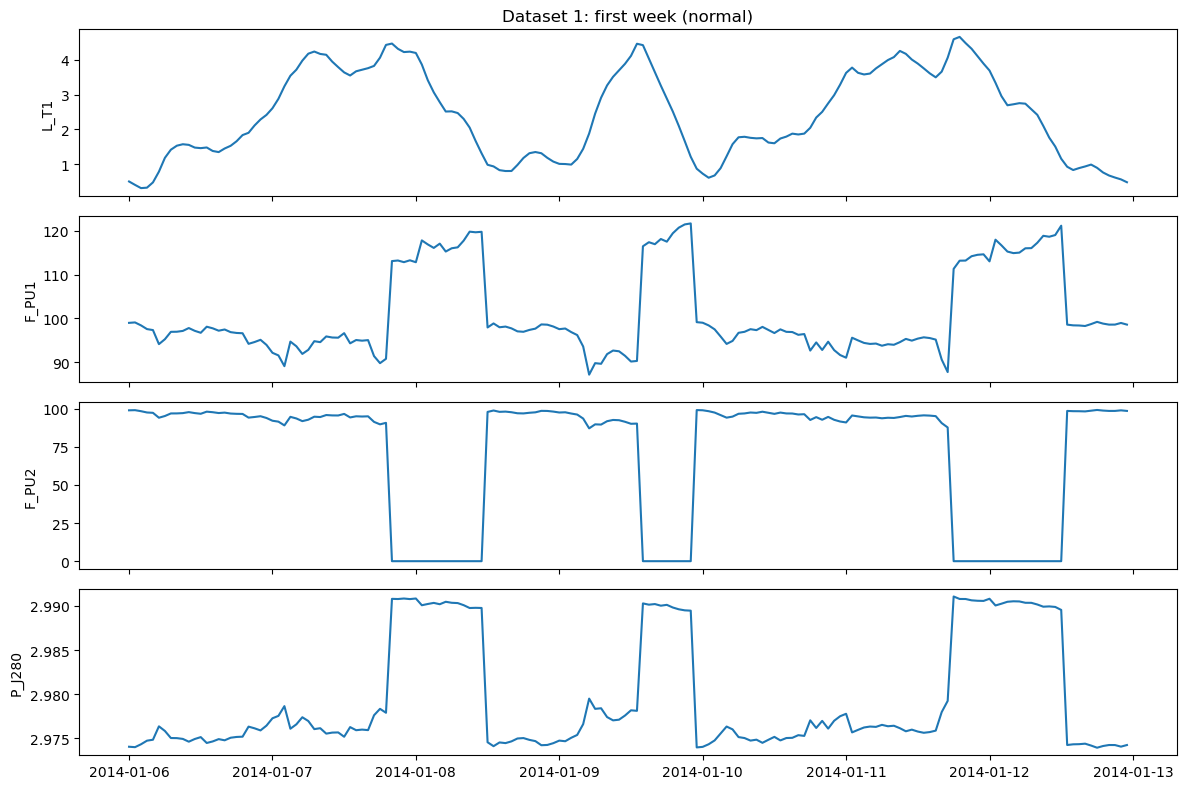

In [14]:
week = dfT1.iloc[:7 * 24]
cols_to_plot = ["L_T1", "F_PU1", "F_PU2", "P_J280"]

fig, axes = plt.subplots(len(cols_to_plot), 1, figsize=(12, 8), sharex=True)

for ax, col in zip(axes, cols_to_plot):
    ax.plot(week["DATETIME"], week[col])
    ax.set_ylabel(col)

axes[0].set_title("Dataset 1: first week (normal)")
plt.tight_layout()
plt.show()

**What this shows:**
- Pump 2 is on most of the time (about 95 to 100) and switches off for about 8 to 19 hours at a time, roughly every 2 days.
- `P_J280` is an exact mirror of pump 2: low when pump 2 is on, high when it is off (the −0.993 correlation).
- Pump 1's flow jumps from about 90–100 to about 113–121 whenever pump 2 is off, so pump 1 takes over the load.
- Tank 1 (`L_T1`) rises and falls in a cycle of about 2 days, not 24 hours. Pump 2 switches off near tank 1's peaks.

So the 12-hour and 24-hour windows are shorter than tank 1's 2-day cycle, and a window sees only part of a cycle. This is only one week.

Caution (check pending): `P_J280` moves only between about 2.974 and 2.991 (a range of 0.017). Dataset 2 and the Test set have at most 2 decimals, so there `P_J280` can only be 2.97, 2.98, or 2.99. After scaling to 0–1, each rounding step is a big jump, which could cause false alarms. Other small-range sensors may have the same problem.

## 5. Attack 1 (13 to 16 Sep 2016)

Why: to see what an attack looks like in the sensors, compared with normal behavior.

### 5a. Which sensors change most

What the code does: takes the Dataset 2 rows inside attack 1's real window (`during`). For each changing sensor, it compares the average during the attack with block A, in block A SDs (same method as step 1c), and prints the top 8 (`change`).

In [15]:
att = attacks[attacks["attack_id"] == 1].iloc[0]
start = att["real_start"]
end = att["real_end"]

during = dfT2[dfT2["DATETIME"].between(start, end)]
print(len(during), "hours in attack 1")

change = (during[varying].mean() - means["A"][varying]) / std_a[varying]
print(change.round(2).sort_values(key=abs, ascending=False).head(8))

50 hours in attack 1
F_PU11    22.98
S_PU11    21.00
F_PU10    -0.90
P_J317     0.76
S_PU10    -0.60
P_J307    -0.29
P_J302    -0.28
L_T1       0.19
dtype: float64


**What this shows:** 50 hours, which matches the attacks table. Top changes:
- `F_PU11` 22.98 and `S_PU11` 21.00. These are huge partly because pump 11's normal SD is tiny, so the number exaggerates the ranking.
- `F_PU10` −0.90 and `S_PU10` −0.60: pump 10 runs less.
- `P_J317` 0.76: rises.
- `P_J307` −0.29 and `P_J302` −0.28: drop together (a near-duplicate pair).
- `L_T1` 0.19: barely moves.

All of these are far bigger than the drift shifts (under 0.1).

Caution: this compares 2016 attack hours with 2014 normal data. Dataset 1 vs Dataset 2 has not been compared yet.

### 5b. Plot around attack 1

What the code does: plots `F_PU10`, `F_PU11`, `P_J317`, and `P_J302` from 3 days before to 2 days after attack 1 (`window`), with the attack shaded. Pump 11 is included because it is at the top of the change list in 5a.

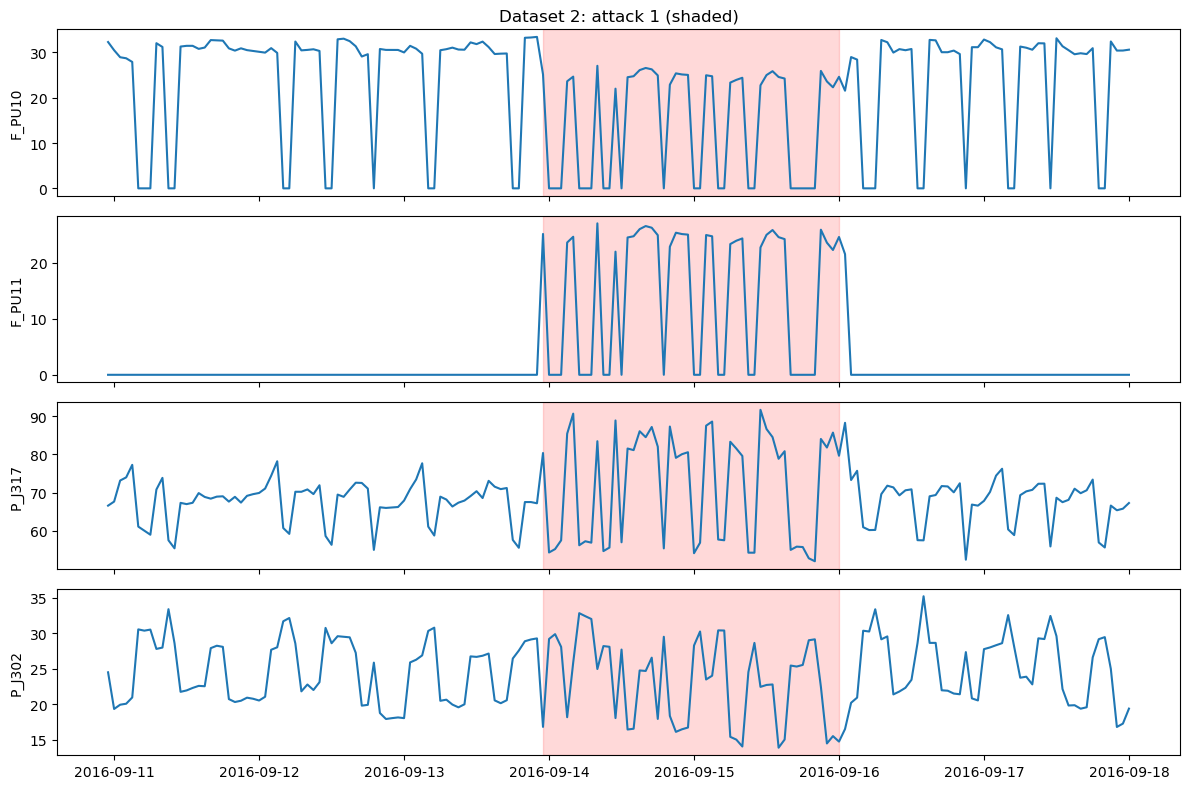

In [16]:
window = dfT2[dfT2["DATETIME"].between(start - pd.Timedelta(days=3), end + pd.Timedelta(days=2))]
cols_to_plot = ["F_PU10", "F_PU11", "P_J317", "P_J302"]

fig, axes = plt.subplots(len(cols_to_plot), 1, figsize=(12, 8), sharex=True)

for ax, col in zip(axes, cols_to_plot):
    ax.plot(window["DATETIME"], window[col])
    ax.axvspan(start, end, color="red", alpha=0.15)
    ax.set_ylabel(col)

axes[0].set_title("Dataset 2: attack 1 (shaded)")
plt.tight_layout()
plt.show()

**What this shows:**
- Pump 11 is off for days before the attack, switches on at the attack start, and switches off right after it ends.
- During the attack, pumps 10 and 11 switch on and off together many times, each at a lower flow (about 25 instead of pump 10's usual 31). Near the end, both stay off for several hours.
- `P_J317` swings much wider than normal (about 53 to 92, compared with about 55 to 78 before the attack).
- `P_J302` becomes more jagged during the attack and dips to about 14, but otherwise stays in a similar range.

So the attack mainly shows up as rapid on/off switching, which is a change in pattern over time. Averages understate this: `P_J317` shifted only 0.76 SD on average but swings much more. Detectors that look at recent history (GRU, Transformer) should suit this kind of attack. The published attack window lines up well with the data, which supports using the windows to rebuild labels.

Cautions: the plot shows real Dataset 2 values, so the "rare pump" caution affects the shift number in 5a but not the plot. Averages can hide attacks that change a sensor's pattern without changing its average.

## End of notebook

The full write-up, with the decisions we need to make and the open items, is in `docs/exploration.md`. The code cell below is empty.